# week5-06 시간 벤치마크 원시 기록 보기

저장된 **시간 측정 JSON만** 읽는 로컬 분석 노트북입니다. GPU·TPU·JAX·PyTorch가 필요하지 않고 장치 실험, 출력 재검증, 모델 연산을 실행하지 않습니다.

- **JAX 통일 실험:** GPU·TPU 모두 JAX/jaxlib 0.11.1.
- **첫 실험:** GPU PyTorch eager, TPU JAX 0.7.2. 프레임워크·버전·세션이 달라 직접적인 프레임워크 성능 실험으로 해석하지 않습니다.
- 두 실험 모두 상주 입력으로 `ReLU(XW+b)`를 호출하고 완료를 기다린 **호스트 지연시간**입니다. 순수 장치 커널 시간이 아닙니다.
- 각 장치·배치에서 seed 5개 × 1,000회 = 5,000개 시간입니다. 이상치를 삭제하지 않습니다.
- v6e1은 할당 실패로 시간 기록이 없습니다.

저장된 셀 출력은 바로 열어볼 수 있습니다. 다시 실행하려면 저장소 루트에서:

```bash
uv sync
uv run --with jupyterlab --with ipykernel jupyter lab notebooks/week5_benchmark_timings.ipynb
```

또는 NumPy·pandas·Matplotlib이 설치된 로컬 Python 커널로 VS Code/Jupyter에서 **Run All**을 실행하세요. 네트워크는 최초 도구 설치에만 필요하며 분석 셀은 로컬 JSON만 읽습니다.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 80)
pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# 저장소 루트 또는 notebooks/에서 실행할 수 있습니다.
REPO_ROOT = None  # 다른 작업 경로에서는 Path('/path/to/tensor2silicon') 지정
if REPO_ROOT is None:
    REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / 'week5/results/2026-10-19-colab-jax').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('REPO_ROOT에 tensor2silicon 저장소 경로를 지정하세요.')
REPO_ROOT = Path(REPO_ROOT).resolve()
EXPERIMENT_DIRS = {
    'jax_unified': REPO_ROOT / 'week5/results/2026-10-19-colab-jax',
    'original_mixed': REPO_ROOT / 'week5/results/2026-10-19-colab',
}
TARGET_ORDER = ['v5e1', 'v6e1', 'A100', 'G4']
print('Repository:', REPO_ROOT)


Repository: /home/jake/tensor2silicon


## 기록 읽기

`result.json`의 `rows[].times_ms`가 원시 호출 시간입니다. `elapsed_s`는 seed별 1,000회 측정 루프의 실제 경과 시간이며 루프 비용도 포함합니다. 아래 셀은 `.npz` 입력·출력 파일을 열지 않습니다.


In [2]:
records, timing_rows, metadata_rows, status_rows = {}, [], [], []
for experiment, folder in EXPERIMENT_DIRS.items():
    for target in TARGET_ORDER:
        path = folder / target / 'results/result.json'
        status_rows.append({'experiment': experiment, 'target': target,
                            'status': 'measured' if path.exists() else 'no timing record',
                            'path': str(path.relative_to(REPO_ROOT))})
        if not path.exists():
            continue
        result = json.loads(path.read_text())
        records[(experiment, target)] = result
        meta = result['meta']
        metadata_rows.append({
            'experiment': experiment, 'target': target, 'device': meta['device_kind'],
            'framework': meta['backend'], 'version': meta['framework_version'],
            'utc': meta['utc'], 'warmup': meta['warmup'],
            'repetitions_per_seed': meta['repetitions_per_seed'],
            'concurrency': meta['concurrency'], 'scope': meta['timing'],
        })
        for row in result['rows']:
            for sample, latency_ms in enumerate(row['times_ms']):
                timing_rows.append({'experiment': experiment, 'target': target,
                                    'M': row['m'], 'seed': row['seed'],
                                    'sample': sample, 'latency_ms': latency_ms,
                                    'latency_us': latency_ms * 1000})
timings = pd.DataFrame(timing_rows)
metadata = pd.DataFrame(metadata_rows)
status = pd.DataFrame(status_rows)
display(status[['experiment', 'target', 'status']])
display(metadata.drop(columns='scope'))
print(f'Loaded {len(timings):,} raw invocation times.')
print(metadata.iloc[0]['scope'])


,experiment,target,status
0,jax_unified,v5e1,measured
1,jax_unified,v6e1,no timing record
2,jax_unified,A100,measured
3,jax_unified,G4,measured
4,original_mixed,v5e1,measured
5,original_mixed,v6e1,no timing record
6,original_mixed,A100,measured
7,original_mixed,G4,measured


,experiment,target,device,framework,version,utc,warmup,repetitions_per_seed,concurrency
0,jax_unified,v5e1,TPU v5 lite,jax,0.11.1,2026-10-19T07:10:01.328676+00:00,50,1000,1
1,jax_unified,A100,NVIDIA A100-SXM4-40GB,jax,0.11.1,2026-10-19T07:09:42.661838+00:00,50,1000,1
2,jax_unified,G4,NVIDIA RTX PRO 6000 Blackwell Server Edition,jax,0.11.1,2026-10-19T07:07:18.848495+00:00,50,1000,1
3,original_mixed,v5e1,TPU v5 lite,jax,0.7.2,2026-10-19T05:48:30.021375+00:00,50,1000,1
4,original_mixed,A100,NVIDIA A100-SXM4-40GB,torch,2.11.0+cu130,2026-10-19T05:48:35.981090+00:00,50,1000,1
5,original_mixed,G4,NVIDIA RTX PRO 6000 Blackwell Server Edition,torch,2.11.0+cu130,2026-10-19T05:48:37.266934+00:00,50,1000,1


Loaded 60,000 raw invocation times.
perf_counter_ns: host invocation through completion, resident X/W/b, no output copy


## 지연시간 요약과 순차 처리량

p50·p95·p99는 seed별 percentile의 평균이 아니라 **seed 5개의 원시 시간을 합쳐** 계산합니다. p99는 이 표본의 관찰값이며 서비스 지연시간 보장이 아닙니다. 처리량은 `완료 호출 수 × M / 총 elapsed_s`입니다. p50의 역수로 계산하지 않습니다. `prepare_and_first_call_s`는 컴파일·캐시 조회·첫 호출이 섞인 준비 기록이며 정상 상태 시간에서 제외됩니다.


In [3]:
summary_rows, seed_rows = [], []
for (experiment, target), result in records.items():
    for row in result['rows']:
        times = np.asarray(row['times_ms'])
        seed_rows.append({
            'experiment': experiment, 'target': target, 'M': row['m'], 'seed': row['seed'],
            'n': len(times), 'p50_ms': np.percentile(times, 50),
            'p95_ms': np.percentile(times, 95), 'mean_ms': times.mean(),
            'elapsed_s': row['elapsed_s'],
            'prepare_plus_first_call_s': row['prepare_and_first_call_s'],
        })
    for m in sorted({r['m'] for r in result['rows']}):
        rows = [r for r in result['rows'] if r['m'] == m]
        times = np.concatenate([r['times_ms'] for r in rows])
        elapsed = sum(r['elapsed_s'] for r in rows)
        summary_rows.append({
            'experiment': experiment, 'target': target, 'M': m, 'n': len(times),
            'min_ms': times.min(), 'p50_ms': np.percentile(times, 50),
            'p95_ms': np.percentile(times, 95), 'p99_ms': np.percentile(times, 99),
            'max_ms': times.max(), 'mean_ms': times.mean(),
            'elapsed_s': elapsed, 'samples_per_s': len(times)*m/elapsed,
        })
summary = pd.DataFrame(summary_rows)
per_seed = pd.DataFrame(seed_rows)
display(summary)


,experiment,target,M,n,min_ms,p50_ms,p95_ms,p99_ms,max_ms,mean_ms,elapsed_s,samples_per_s
0,jax_unified,v5e1,1,5000,0.122980,0.162505,0.196320,0.218316,0.264479,0.164061,0.827656,6.041157e+03
1,jax_unified,v5e1,128,5000,0.124780,0.151620,0.172681,0.193317,0.282200,0.151235,0.763141,8.386387e+05
2,jax_unified,A100,1,5000,0.081056,0.098612,0.148289,0.160971,0.261854,0.108015,0.547939,9.125098e+03
3,jax_unified,A100,128,5000,0.091474,0.109679,0.147513,0.159578,0.445795,0.117339,0.595151,1.075356e+06
4,jax_unified,G4,1,5000,0.024810,0.026230,0.028320,0.032440,0.126430,0.026476,0.133947,3.732825e+04
5,jax_unified,G4,128,5000,0.028970,0.043605,0.045100,0.048400,0.362040,0.043498,0.218991,2.922496e+06
6,original_mixed,v5e1,1,5000,0.104510,0.130180,0.150801,0.168362,0.240490,0.132777,0.670017,7.462501e+03
7,original_mixed,v5e1,128,5000,0.109080,0.138865,0.161801,0.179750,0.304180,0.137717,0.695175,9.206315e+05
8,original_mixed,A100,1,5000,0.052830,0.055047,0.070979,0.085043,0.269677,0.057425,0.291206,1.717001e+04
9,original_mixed,A100,128,5000,0.053738,0.056509,0.072322,0.089060,0.221263,0.059099,0.299609,2.136115e+06


## 표시 대상 선택

아래 설정을 바꾸고 이후 셀을 실행하세요. 원시 데이터와 전체 요약표는 그대로 유지됩니다. 그래프는 선택한 실험·장치·seed만 표시합니다.


In [4]:
EXPERIMENT = 'jax_unified'  # 또는 'original_mixed'
TARGETS = ['v5e1', 'A100', 'G4']
BATCHES = [1, 128]
SEEDS = [0, 1, 2, 3, 4]

view = timings.loc[
    (timings['experiment'] == EXPERIMENT)
    & timings['target'].isin(TARGETS)
    & timings['M'].isin(BATCHES)
    & timings['seed'].isin(SEEDS)
].copy()
if view.empty:
    raise ValueError('선택한 조건에 시간 기록이 없습니다. v6e1은 미측정입니다.')
print(f'{EXPERIMENT}: {len(view):,} samples; targets={TARGETS}; seeds={SEEDS}')
display(view.groupby(['target', 'M'], sort=False)['latency_ms'].agg(['count', 'median', 'mean', 'min', 'max']))


jax_unified: 30,000 samples; targets=['v5e1', 'A100', 'G4']; seeds=[0, 1, 2, 3, 4]


count    median      mean       min       max
target M                                                 
v5e1   1     5000  0.162505  0.164061  0.122980  0.264479
       128   5000  0.151620  0.151235  0.124780  0.282200
A100   1     5000  0.098612  0.108015  0.081056  0.261854
       128   5000  0.109679  0.117339  0.091474  0.445795
G4     1     5000  0.026230  0.026476  0.024810  0.126430
       128   5000  0.043605  0.043498  0.028970  0.362040

## 전체 지연시간 분포 — ECDF

가로축은 µs의 로그 스케일, 세로축은 해당 시간 이하인 호출의 비율입니다. 각 선택 그룹의 최대값까지 모든 표본을 표시하므로 긴 꼬리도 볼 수 있습니다.


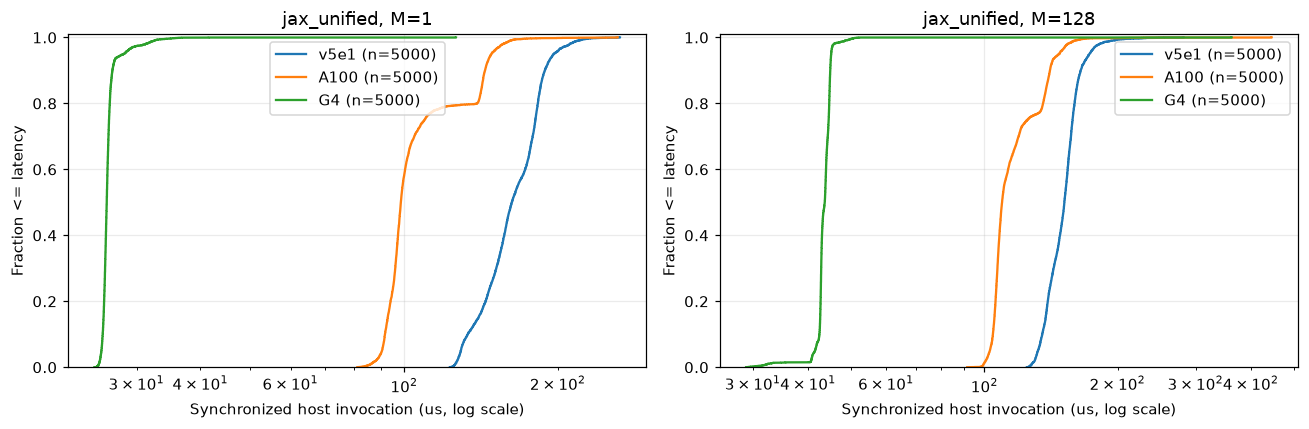

In [5]:
fig, axes = plt.subplots(1, len(BATCHES), figsize=(6*len(BATCHES), 4), squeeze=False)
for ax, m in zip(axes.ravel(), BATCHES):
    for target in TARGETS:
        values = np.sort(view.loc[(view['target'] == target) & (view['M'] == m), 'latency_us'].to_numpy())
        if len(values):
            ax.step(values, np.arange(1, len(values)+1)/len(values), where='post', label=f'{target} (n={len(values)})')
    ax.set_xscale('log')
    ax.set(xlabel='Synchronized host invocation (us, log scale)', ylabel='Fraction <= latency',
           title=f'{EXPERIMENT}, M={m}', ylim=(0, 1.01))
    if ax.lines:
        ax.legend()
fig.tight_layout()
plt.show()


## 호출 순서와 seed별 변화

각 seed 내부의 호출 순서는 보존합니다. 가로축은 seed별 표본을 이어 붙인 순서이며 점선은 seed 경계입니다. seed 사이에는 입력 로드·컴파일·준비 실행이 있으므로 전체 벽시계 시간축은 아닙니다. 세로축 로그 스케일로 모든 이상치를 표시합니다.


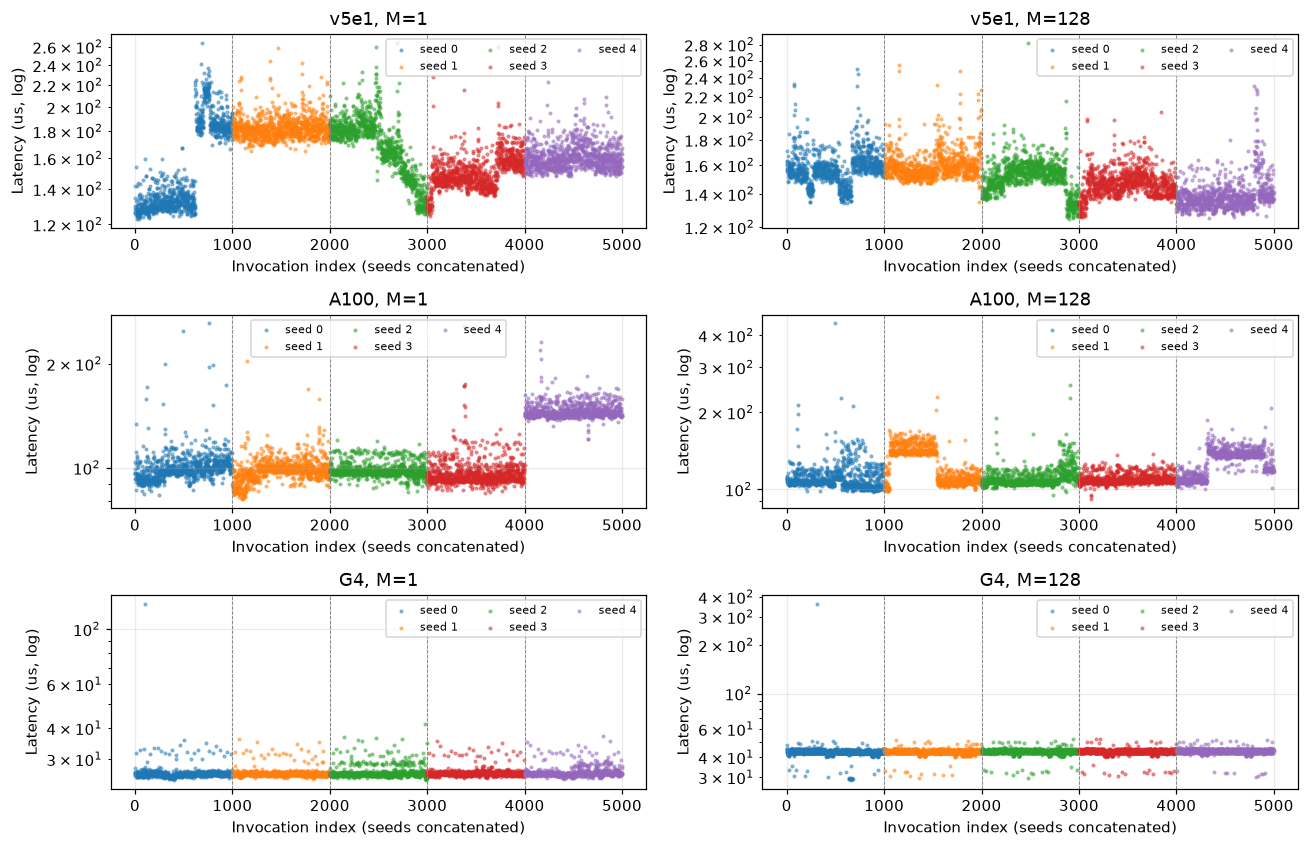

In [6]:
fig, axes = plt.subplots(len(TARGETS), len(BATCHES), figsize=(6*len(BATCHES), 2.6*len(TARGETS)), squeeze=False)
for i, target in enumerate(TARGETS):
    for j, m in enumerate(BATCHES):
        ax, offset = axes[i, j], 0
        for seed in SEEDS:
            selected = view.loc[(view['target'] == target) & (view['M'] == m) & (view['seed'] == seed)].sort_values('sample')
            if selected.empty:
                continue
            if offset:
                ax.axvline(offset, color='gray', linewidth=.6, linestyle='--')
            ax.scatter(offset + np.arange(len(selected)), selected['latency_us'], s=3, alpha=.45, label=f'seed {seed}')
            offset += len(selected)
        ax.set_yscale('log')
        ax.set(title=f'{target}, M={m}', xlabel='Invocation index (seeds concatenated)', ylabel='Latency (us, log)')
        if offset:
            ax.legend(ncol=3, fontsize=7)
fig.tight_layout()
plt.show()


In [7]:
seed_view = per_seed.loc[(per_seed['experiment'] == EXPERIMENT)
                        & per_seed['target'].isin(TARGETS)
                        & per_seed['M'].isin(BATCHES)
                        & per_seed['seed'].isin(SEEDS)]
display(seed_view)


,experiment,target,M,seed,n,p50_ms,p95_ms,mean_ms,elapsed_s,prepare_plus_first_call_s
0,jax_unified,v5e1,1,0,1000,0.136650,0.211795,0.155218,0.156633,0.338121
1,jax_unified,v5e1,1,1,1000,0.181606,0.198578,0.183024,0.184728,0.001923
2,jax_unified,v5e1,1,2,1000,0.174825,0.200577,0.169757,0.171317,0.002042
3,jax_unified,v5e1,1,3,1000,0.149444,0.170587,0.151150,0.152435,0.001856
4,jax_unified,v5e1,1,4,1000,0.159170,0.177847,0.161156,0.162543,0.001802
5,jax_unified,v5e1,128,0,1000,0.156750,0.176710,0.157737,0.159130,0.176118
6,jax_unified,v5e1,128,1,1000,0.157400,0.179819,0.160204,0.161667,0.001911
7,jax_unified,v5e1,128,2,1000,0.152760,0.167126,0.151783,0.153184,0.001915
8,jax_unified,v5e1,128,3,1000,0.146235,0.161952,0.147036,0.148347,0.001742
9,jax_unified,v5e1,128,4,1000,0.137030,0.158375,0.139414,0.140813,0.001759


## 원시 호출 시간과 가장 느린 호출

`view`에는 선택한 모든 원시 시간이 들어 있습니다. `sample`은 seed 내부에서 0부터 시작하는 호출 번호입니다. 아래는 첫 20개와 가장 느린 20개입니다. 필요하면 셀에서 `view`를 직접 필터링하거나 마지막 셀에서 CSV로 저장할 수 있습니다.


In [8]:
display(view.head(20))
display(view.nlargest(20, 'latency_ms'))


,experiment,target,M,seed,sample,latency_ms,latency_us
0,jax_unified,v5e1,1,0,0,0.126050,126.050
1,jax_unified,v5e1,1,0,1,0.130280,130.280
2,jax_unified,v5e1,1,0,2,0.134790,134.790
3,jax_unified,v5e1,1,0,3,0.128630,128.630
4,jax_unified,v5e1,1,0,4,0.126750,126.750
5,jax_unified,v5e1,1,0,5,0.141580,141.580
6,jax_unified,v5e1,1,0,6,0.154310,154.310
7,jax_unified,v5e1,1,0,7,0.129240,129.240
8,jax_unified,v5e1,1,0,8,0.128100,128.100
9,jax_unified,v5e1,1,0,9,0.132690,132.690


,experiment,target,M,seed,sample,latency_ms,latency_us
15491,jax_unified,A100,128,0,491,0.445795,445.795
25312,jax_unified,G4,128,0,312,0.362040,362.040
7476,jax_unified,v5e1,128,2,476,0.282200,282.200
2694,jax_unified,v5e1,1,2,694,0.264479,264.479
688,jax_unified,v5e1,1,0,688,0.264390,264.390
10759,jax_unified,A100,1,0,759,0.261854,261.854
3730,jax_unified,v5e1,1,3,730,0.260200,260.200
2479,jax_unified,v5e1,1,2,479,0.260150,260.150
1468,jax_unified,v5e1,1,1,468,0.258320,258.320
13379,jax_unified,A100,1,3,379,0.257945,257.945


## 첫 실험과 JAX 통일 실험 비교

두 실험의 **전체 seed**로 계산한 p50/p95를 나란히 보여줍니다. 위 그래프 필터와 독립적입니다. GPU 프레임워크뿐 아니라 세션·호스트 상태·컴파일 경로, TPU의 JAX 버전도 바뀌었으므로 시간 차이를 프레임워크만의 효과로 해석하지 않습니다.


p50_ms                     p95_ms                 \
experiment jax_unified original_mixed jax_unified original_mixed   
target M                                                           
A100   1      0.098612       0.055047    0.148289       0.070979   
       128    0.109679       0.056509    0.147513       0.072322   
G4     1      0.026230       0.019260    0.028320       0.020000   
       128    0.043605       0.024420    0.045100       0.024540   
v5e1   1      0.162505       0.130180    0.196320       0.150801   
       128    0.151620       0.138865    0.172681       0.161801   

           samples_per_s                 
experiment   jax_unified original_mixed  
target M                                 
A100   1    9.125098e+03   1.717001e+04  
       128  1.075356e+06   2.136115e+06  
G4     1    3.732825e+04   5.240111e+04  
       128  2.922496e+06   5.287952e+06  
v5e1   1    6.041157e+03   7.462501e+03  
       128  8.386387e+05   9.206315e+05

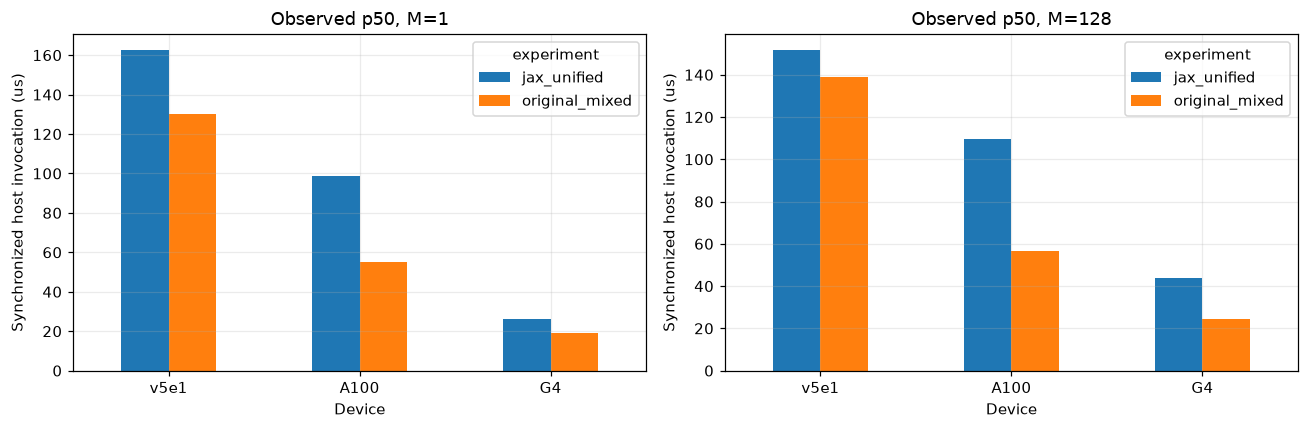

In [9]:
display(summary.pivot(index=['target', 'M'], columns='experiment', values=['p50_ms', 'p95_ms', 'samples_per_s']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), squeeze=False)
for ax, m in zip(axes.ravel(), [1, 128]):
    table = summary.loc[summary['M'] == m].pivot(index='target', columns='experiment', values='p50_ms')
    table = table.reindex([t for t in TARGET_ORDER if t in table.index]) * 1000
    table.plot.bar(ax=ax, rot=0)
    ax.set(title=f'Observed p50, M={m}', ylabel='Synchronized host invocation (us)', xlabel='Device')
fig.tight_layout()
plt.show()


## 원본 JSON과 할당 실패 기록

장치·실험·배치·seed를 지정해 해당 JSON의 시간 필드를 직접 확인할 수 있습니다. 여기서는 큰 `times_ms` 목록의 앞 10개만 출력하며 전체 목록은 `raw_row['times_ms']`에 있습니다. 할당 실패 기록은 시간 결과로 섞지 않고 별도로 표시합니다.


In [10]:
INSPECT_EXPERIMENT, INSPECT_TARGET, INSPECT_M, INSPECT_SEED = 'jax_unified', 'G4', 128, 0
raw_result = records[(INSPECT_EXPERIMENT, INSPECT_TARGET)]
raw_row = next(r for r in raw_result['rows'] if r['m'] == INSPECT_M and r['seed'] == INSPECT_SEED)
time_fields = ['m', 'seed', 'prepare_and_first_call_s', 'p50_ms', 'p95_ms', 'mean_ms', 'elapsed_s', 'samples_per_s']
print(json.dumps({k: raw_row[k] for k in time_fields}, indent=2))
print('times_ms[:10] =', raw_row['times_ms'][:10])
for experiment, folder in EXPERIMENT_DIRS.items():
    path = folder / 'allocation-status.json'
    if path.exists():
        allocation = json.loads(path.read_text())
        print(experiment, 'v6e1:', json.dumps(allocation.get('v6e1', {}), ensure_ascii=False, indent=2))


{
  "m": 128,
  "seed": 0,
  "prepare_and_first_call_s": 0.48705974399990737,
  "p50_ms": 0.04294,
  "p95_ms": 0.04497,
  "mean_ms": 0.043373184,
  "elapsed_s": 0.043762674,
  "samples_per_s": 2924866.976821389
}
times_ms[:10] = [0.04494, 0.04518, 0.04808, 0.04488, 0.04305, 0.04353, 0.04281, 0.04384, 0.04298, 0.04122]
jax_unified v6e1: {
  "attempts": 2,
  "first_error": "HTTP 502 Bad Gateway",
  "second_attempt": "HTTP 502 Bad Gateway",
  "http_timeout_s": 600,
  "automatic_retries": 0,
  "status": "allocation_failed"
}
original_mixed v6e1: {
  "initial_cli_version": "0.7.4",
  "failed_attempts": 3,
  "failure": "requests.exceptions.ReadTimeout (read timeout=120)",
  "updated_cli_version": "0.7.5.dev9+g006ff96ac",
  "updated_cli_commit": "006ff96ac2d0e4dcfb702467a76493d687929be8",
  "request_timeout_s": 600,
  "automatic_retries": 0,
  "status": "reallocation_failed_http_502",
  "additional_user_wait_limit_s": 60,
  "measurement": "not_run",
  "cancellation": "stop command completed; 

## 선택 사항: CSV 내보내기

기본값은 저장하지 않습니다. `EXPORT=True`로 바꾸면 선택한 원시 시간과 전체 요약·seed별 표를 `week5/timing_exports/`에 저장합니다. 원본 결과 파일은 수정하지 않습니다.


In [11]:
EXPORT = False
if EXPORT:
    export_dir = REPO_ROOT / 'week5/timing_exports'
    export_dir.mkdir(parents=True, exist_ok=True)
    view.to_csv(export_dir / f'{EXPERIMENT}_selected_raw_times.csv', index=False)
    summary.to_csv(export_dir / 'all_experiments_summary.csv', index=False)
    per_seed.to_csv(export_dir / 'all_experiments_per_seed.csv', index=False)
    print('Exported to', export_dir)
else:
    print('CSV export disabled; no files changed.')


CSV export disabled; no files changed.
